# Fire Detection from Camera Images
### Applied Artificial Neural Network — CNN project

This notebook builds a binary image classifier that estimates whether a camera image contains **fire** or **no fire**. It covers the end-to-end workflow: dataset inspection, preprocessing, CNN design, training with regularization, validation, metrics, and prediction on a new image.

> **Safety note:** This is an educational image-classification prototype. It is not a certified alarm, does not monitor live cameras, and must not be used as the sole fire-safety system.

### Learning outcomes
- Explain why convolution and pooling are useful for images.
- Train a CNN using backpropagation, binary cross-entropy, and Adam.
- Apply augmentation, batch normalization, dropout, class weighting, and early stopping.
- Evaluate with class-wise precision/recall, a confusion matrix, and ROC AUC.


## Syllabus connection

| Unit | Concepts used here |
|---|---|
| I — Deep Learning | Applied computer-vision task using TensorFlow/Keras. |
| II — DNN Fundamentals | ReLU hidden activations, sigmoid output, binary cross-entropy, gradient descent/backpropagation. |
| III — Optimization | Adam, class weighting, data augmentation, dropout, batch normalization, learning-rate reduction, early stopping. |
| IV — CNNs | Convolution, feature maps, max pooling, hierarchical image features. |
| V — Sequence Models | Not part of this still-image baseline; a later version could classify video frame sequences with an RNN or temporal CNN. |

The project brief describes a Fire Dataset of about 1,000 images. The dataset files were not supplied, so add the dataset in the structure below before running the data-loading cells.


## 1. Dataset setup

Place the notebook in a project folder and organize images into class subfolders. The class names and ordering below are intentional: `fire` is class 1 and is the positive class for the sigmoid output.

```text
data/fire_dataset/
├── nofire/
│   ├── image_001.jpg
│   └── ...
└── fire/
    ├── image_001.jpg
    └── ...
```

Use only images you are permitted to use, and record the dataset source and license in your submission. If possible, split by source video, camera, or location to avoid near-duplicate frames leaking between training and validation.


The notebook uses a stratified **70% training, 15% validation, 15% test** split. The test set is held out until final evaluation. The split is by image; if your images come from videos or multiple cameras, split by video/camera to reduce near-duplicate leakage.


In [1]:
from google.colab import drive
from pathlib import Path
from zipfile import ZipFile

drive.mount("/content/drive")

with ZipFile("/content/drive/MyDrive/Fire-Detection-Dataset-master.zip") as archive:
    archive.extractall("/content/data")

Mounted at /content/drive


In [2]:
# If needed, install the notebook dependencies in your environment:
# %pip install tensorflow scikit-learn matplotlib pillow

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

SEED = 42
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 20
CLASS_NAMES = ["nofire", "fire"]  # Dataset folder names; sigmoid target: fire = 1
DATA_ROOT = Path("/content/data") if Path("/content/data").exists() else Path("data")
# Find the directory containing both class folders, including nested ZIP layouts.
search_dirs = [DATA_ROOT] + [p for p in DATA_ROOT.rglob("*") if p.is_dir()]
DATA_DIR = next((p for p in search_dirs if all((p / name).is_dir() for name in CLASS_NAMES)), None)
ARTIFACT_DIR = Path("/content/drive/MyDrive/firewatch_artifacts") if Path("/content/drive").exists() else Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Dataset search root:", DATA_ROOT.resolve())
print("Detected dataset folder:", DATA_DIR.resolve() if DATA_DIR else "not found")


TensorFlow: 2.21.0
Dataset search root: /content/data
Detected dataset folder: /content/data/Fire-Detection-Dataset-master


In [3]:
# Create independent, stratified 70/15/15 train/validation/test splits.
from sklearn.model_selection import train_test_split

if DATA_DIR is None:
    raise FileNotFoundError(
        f"Could not find sibling folders {CLASS_NAMES} under {DATA_ROOT.resolve()}. "
        "Extract the dataset under /content/data (Colab) or data/ (local), then rerun this cell."
    )

# Gather image file paths and their labels (nofire=0, fire=1).
valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
file_paths, file_labels = [], []
for class_index, class_name in enumerate(CLASS_NAMES):
    for image_path in sorted((DATA_DIR / class_name).rglob("*")):
        if image_path.is_file() and image_path.suffix.lower() in valid_extensions:
            file_paths.append(str(image_path))
            file_labels.append(class_index)

file_paths = np.asarray(file_paths)
file_labels = np.asarray(file_labels, dtype=np.int32)
if len(file_paths) == 0:
    raise ValueError(f"No supported images found in {DATA_DIR}")

# Reserve 15% for test, then 15% overall for validation.
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    file_paths, file_labels, test_size=0.15, random_state=SEED, stratify=file_labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths, train_val_labels, test_size=(0.15 / 0.85),
    random_state=SEED, stratify=train_val_labels
)

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, tf.cast(label, tf.float32)

def make_dataset(paths, labels, training=False):
    labels = np.asarray(labels, dtype=np.float32).reshape(-1, 1)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

def show_class_counts(split_name, labels):
    counts = np.bincount(labels, minlength=len(CLASS_NAMES))
    print(f"{split_name} ({len(labels)} images):", dict(zip(CLASS_NAMES, counts.tolist())))
    if np.any(counts == 0):
        raise ValueError(f"{split_name} must contain images from both classes")

show_class_counts("Train", train_labels)
show_class_counts("Validation", val_labels)
show_class_counts("Test", test_labels)


Train (1754 images): {'nofire': 865, 'fire': 889}
Validation (376 images): {'nofire': 185, 'fire': 191}
Test (376 images): {'nofire': 185, 'fire': 191}


{'nofire': 865, 'fire': 889}


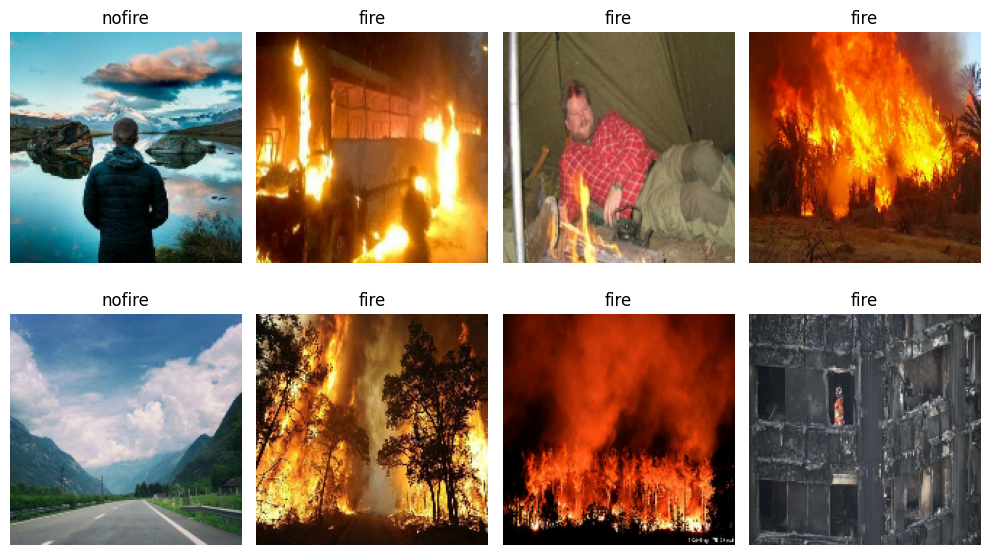

In [4]:
# Inspect examples and check class balance in the training split.
class_counts = np.zeros(len(CLASS_NAMES), dtype=int)
for _, labels in train_ds:
    class_counts += np.bincount(labels.numpy().reshape(-1).astype(int), minlength=len(CLASS_NAMES))
print(dict(zip(CLASS_NAMES, class_counts.tolist())))

images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
# Prefetch data to keep the input pipeline efficient.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Balanced class weights help when one class has fewer training images.
counts = np.bincount(np.concatenate([y.numpy().reshape(-1) for _, y in train_ds]).astype(int), minlength=2)
if np.any(counts == 0):
    raise ValueError("Both classes must be present in the training split.")
class_weight = {i: float(counts.sum() / (len(counts) * count)) for i, count in enumerate(counts)}
print("Training counts:", dict(zip(CLASS_NAMES, counts.tolist())))
print("Class weights:", class_weight)


Training counts: {'nofire': 865, 'fire': 889}
Class weights: {0: 1.0138728323699422, 1: 0.9865016872890888}


In [6]:
# CNN: convolutional feature extraction, pooling, and a sigmoid binary classifier.
def build_model(image_size=IMAGE_SIZE):
    inputs = tf.keras.Input(shape=(*image_size, 3), name="camera_image")
    x = tf.keras.layers.Rescaling(1.0 / 255, name="normalize_pixels")(inputs)
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.04),
        tf.keras.layers.RandomZoom(0.08),
        tf.keras.layers.RandomContrast(0.08),
    ], name="training_augmentation")
    x = augmentation(x)

    for block, filters in enumerate((32, 64, 128), start=1):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv_{block}_a")(x)
        x = tf.keras.layers.BatchNormalization(name=f"batch_norm_{block}_a")(x)
        x = tf.keras.layers.Activation("relu", name=f"relu_{block}_a")(x)
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv_{block}_b")(x)
        x = tf.keras.layers.BatchNormalization(name=f"batch_norm_{block}_b")(x)
        x = tf.keras.layers.Activation("relu", name=f"relu_{block}_b")(x)
        x = tf.keras.layers.MaxPooling2D(2, name=f"max_pool_{block}")(x)
        if block < 3:
            x = tf.keras.layers.Dropout(0.15, name=f"dropout_{block}")(x)

    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pool")(x)
    x = tf.keras.layers.Dense(128, activation="relu", name="dense_features")(x)
    x = tf.keras.layers.Dropout(0.4, name="classifier_dropout")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="fire_probability")(x)
    return tf.keras.Model(inputs, outputs, name="fire_detection_cnn")

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc"),
    ],
)
model.summary()


Model: "fire_detection_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camera_image (InputLayer)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize_pixels (Rescaling)    │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_a (Conv2D)               │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1_a                  │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1_a (Activation)           │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1_b (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1_b                  │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1_b (Activation)           │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_1 (MaxPooling2D)       │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_a (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2_a                  │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2_a (Activation)           │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2_b (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2_b                  │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2_b (Activation)           │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_2 (MaxPooling2D)       │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3_a (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3_a                  │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3_a (Activation)           │ (None, 40, 40, 128)    │             

 Total params: 304,993 (1.16 MB)

 Trainable params: 304,097 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [7]:
# Save the best validation-AUC model; stop when validation loss stops improving.
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        ARTIFACT_DIR / "fire_classifier.keras",
        monitor="val_auc", mode="max", save_best_only=True,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)


Epoch 1/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 39s 423ms/step - accuracy: 0.7856 - auc: 0.8673 - loss: 0.4583 - precision: 0.8132 - recall: 0.7492 - val_accuracy: 0.5186 - val_auc: 0.6689 - val_loss: 0.7295 - val_precision: 0.5134 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 24s 436ms/step - accuracy: 0.8466 - auc: 0.9189 - loss: 0.3647 - precision: 0.8647 - recall: 0.8268 - val_accuracy: 0.5319 - val_auc: 0.7827 - val_loss: 0.7876 - val_precision: 0.5204 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 43s 463ms/step - accuracy: 0.8637 - auc: 0.9326 - loss: 0.3293 - precision: 0.8860 - recall: 0.8391 - val_accuracy: 0.5080 - val_auc: 0.7875 - val_loss: 0.7310 - val_precision: 0.5081 - val_recall: 0.9843 - learning_rate: 0.0010
Epoch 4/20
55/55 ━━━━━━━━━━━━━━━━━━━━ 22s 395ms/step - accuracy: 0.8905 - auc: 0.9496 - loss: 0.2850 - precision: 0.8965 - recall: 0.8864 - val_accuracy: 0.4920 - val_auc: 0.5547 - val_loss: 0.8403 -

In [8]:
# Report training and validation accuracy during model selection.
# Keep the test set untouched until the final evaluation cell below.
best_model = tf.keras.models.load_model(ARTIFACT_DIR / "fire_classifier.keras")
train_metrics = best_model.evaluate(train_ds, verbose=0, return_dict=True)
validation_metrics = best_model.evaluate(val_ds, verbose=0, return_dict=True)

print(f"Train accuracy: {train_metrics['accuracy'] * 100:.2f}%")
print(f"Validation accuracy: {validation_metrics['accuracy'] * 100:.2f}%")


Train accuracy: 95.04%
Validation accuracy: 92.82%


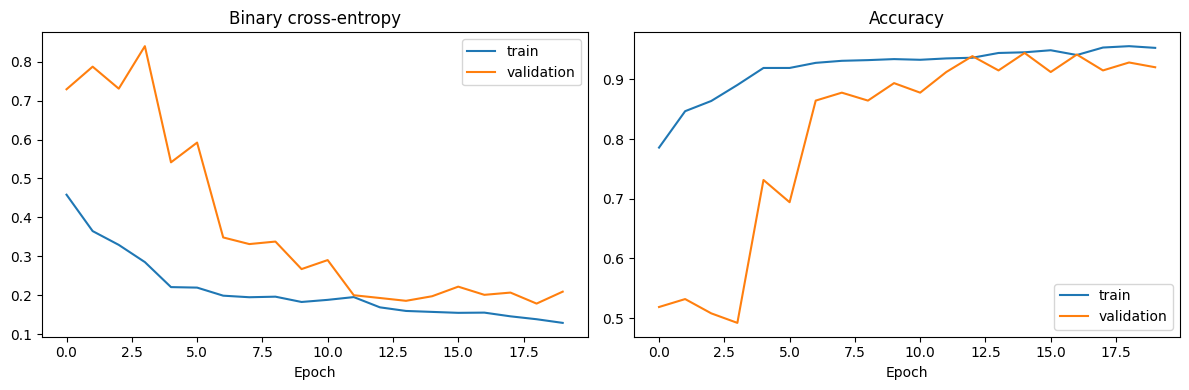

In [9]:
# Plot training and validation loss/accuracy to inspect overfitting.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Binary cross-entropy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

      nofire       0.91      0.95      0.93       185
        fire       0.95      0.91      0.93       191

    accuracy                           0.93       376
   macro avg       0.93      0.93      0.93       376
weighted avg       0.93      0.93      0.93       376



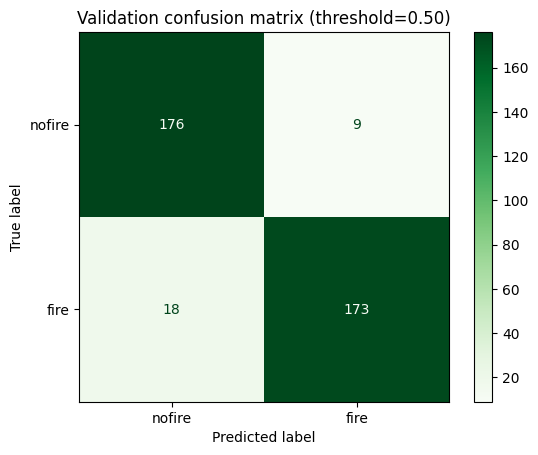

Validation ROC AUC: 0.9838


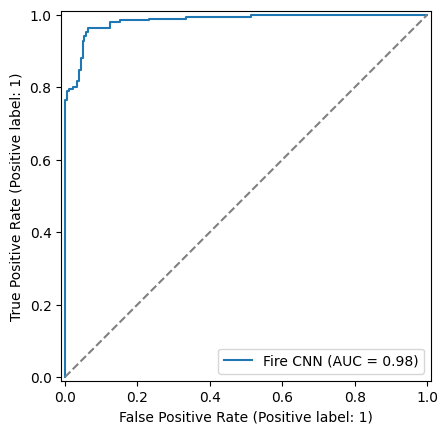

In [10]:
# Evaluate the best saved checkpoint at a baseline threshold of 0.50.
best_model = tf.keras.models.load_model(ARTIFACT_DIR / "fire_classifier.keras")
y_true = np.concatenate([y.numpy().reshape(-1) for _, y in val_ds]).astype(int)
y_score = best_model.predict(val_ds, verbose=0).reshape(-1)
evaluation_threshold = 0.50
y_pred = (y_score >= evaluation_threshold).astype(int)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Greens", values_format="d")
plt.title(f"Validation confusion matrix (threshold={evaluation_threshold:.2f})")
plt.show()
if len(np.unique(y_true)) == 2:
    print("Validation ROC AUC:", round(roc_auc_score(y_true, y_score), 4))
    RocCurveDisplay.from_predictions(y_true, y_score, name="Fire CNN")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.show()


## 7. Interpret the results

Pay special attention to **fire recall** and the fire false-negative count: a false negative is a fire image classified as no-fire. Precision describes how many images flagged as fire were actually fire. Accuracy alone can be misleading with imbalanced classes.

The default threshold of 0.50 is only a baseline. If you change it, select the threshold using representative validation data and describe the precision/recall trade-off. Never use this prototype as a standalone safety system.


In [11]:
# Save class order and a compact validation summary beside the trained model.
summary = {
    "class_names": CLASS_NAMES,
    "threshold": evaluation_threshold,
    "confusion_matrix_labels": CLASS_NAMES,
    "confusion_matrix": cm.tolist(),
    "roc_auc": float(roc_auc_score(y_true, y_score)) if len(np.unique(y_true)) == 2 else None,
}
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "labels.json").write_text(json.dumps({"class_names": CLASS_NAMES}, indent=2), encoding="utf-8")
print("Saved artifacts to:", ARTIFACT_DIR.resolve())


Saved artifacts to: /content/drive/MyDrive/firewatch_artifacts


In [12]:
# 1. Compare thresholds: fire precision, recall, and F2 score
threshold_rows = []

for candidate_threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (y_score >= candidate_threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f2 = (
        5 * precision * recall / (4 * precision + recall)
        if (4 * precision + recall) else 0.0
    )
    threshold_rows.append((candidate_threshold, precision, recall, f2, fp, fn))

print("Threshold | Fire precision | Fire recall | F2 | False positives | False negatives")
for threshold, precision, recall, f2, fp, fn in threshold_rows:
    print(
        f"{threshold:.2f}      | {precision:.3f}          | {recall:.3f}     "
        f"| {f2:.3f} | {fp}               | {fn}"
    )

Threshold | Fire precision | Fire recall | F2 | False positives | False negatives
0.10      | 0.934          | 0.963     | 0.957 | 13               | 7
0.15      | 0.938          | 0.958     | 0.954 | 12               | 8
0.20      | 0.943          | 0.953     | 0.951 | 11               | 9
0.25      | 0.943          | 0.953     | 0.951 | 11               | 9
0.30      | 0.942          | 0.942     | 0.942 | 11               | 11
0.35      | 0.947          | 0.932     | 0.935 | 10               | 13
0.40      | 0.947          | 0.927     | 0.931 | 10               | 14
0.45      | 0.951          | 0.916     | 0.923 | 9               | 16
0.50      | 0.951          | 0.906     | 0.914 | 9               | 18
0.55      | 0.950          | 0.901     | 0.910 | 9               | 19
0.60      | 0.950          | 0.890     | 0.901 | 9               | 21
0.65      | 0.949          | 0.880     | 0.893 | 9               | 23
0.70      | 0.953          | 0.859     | 0.876 | 8               | 27
0.75 

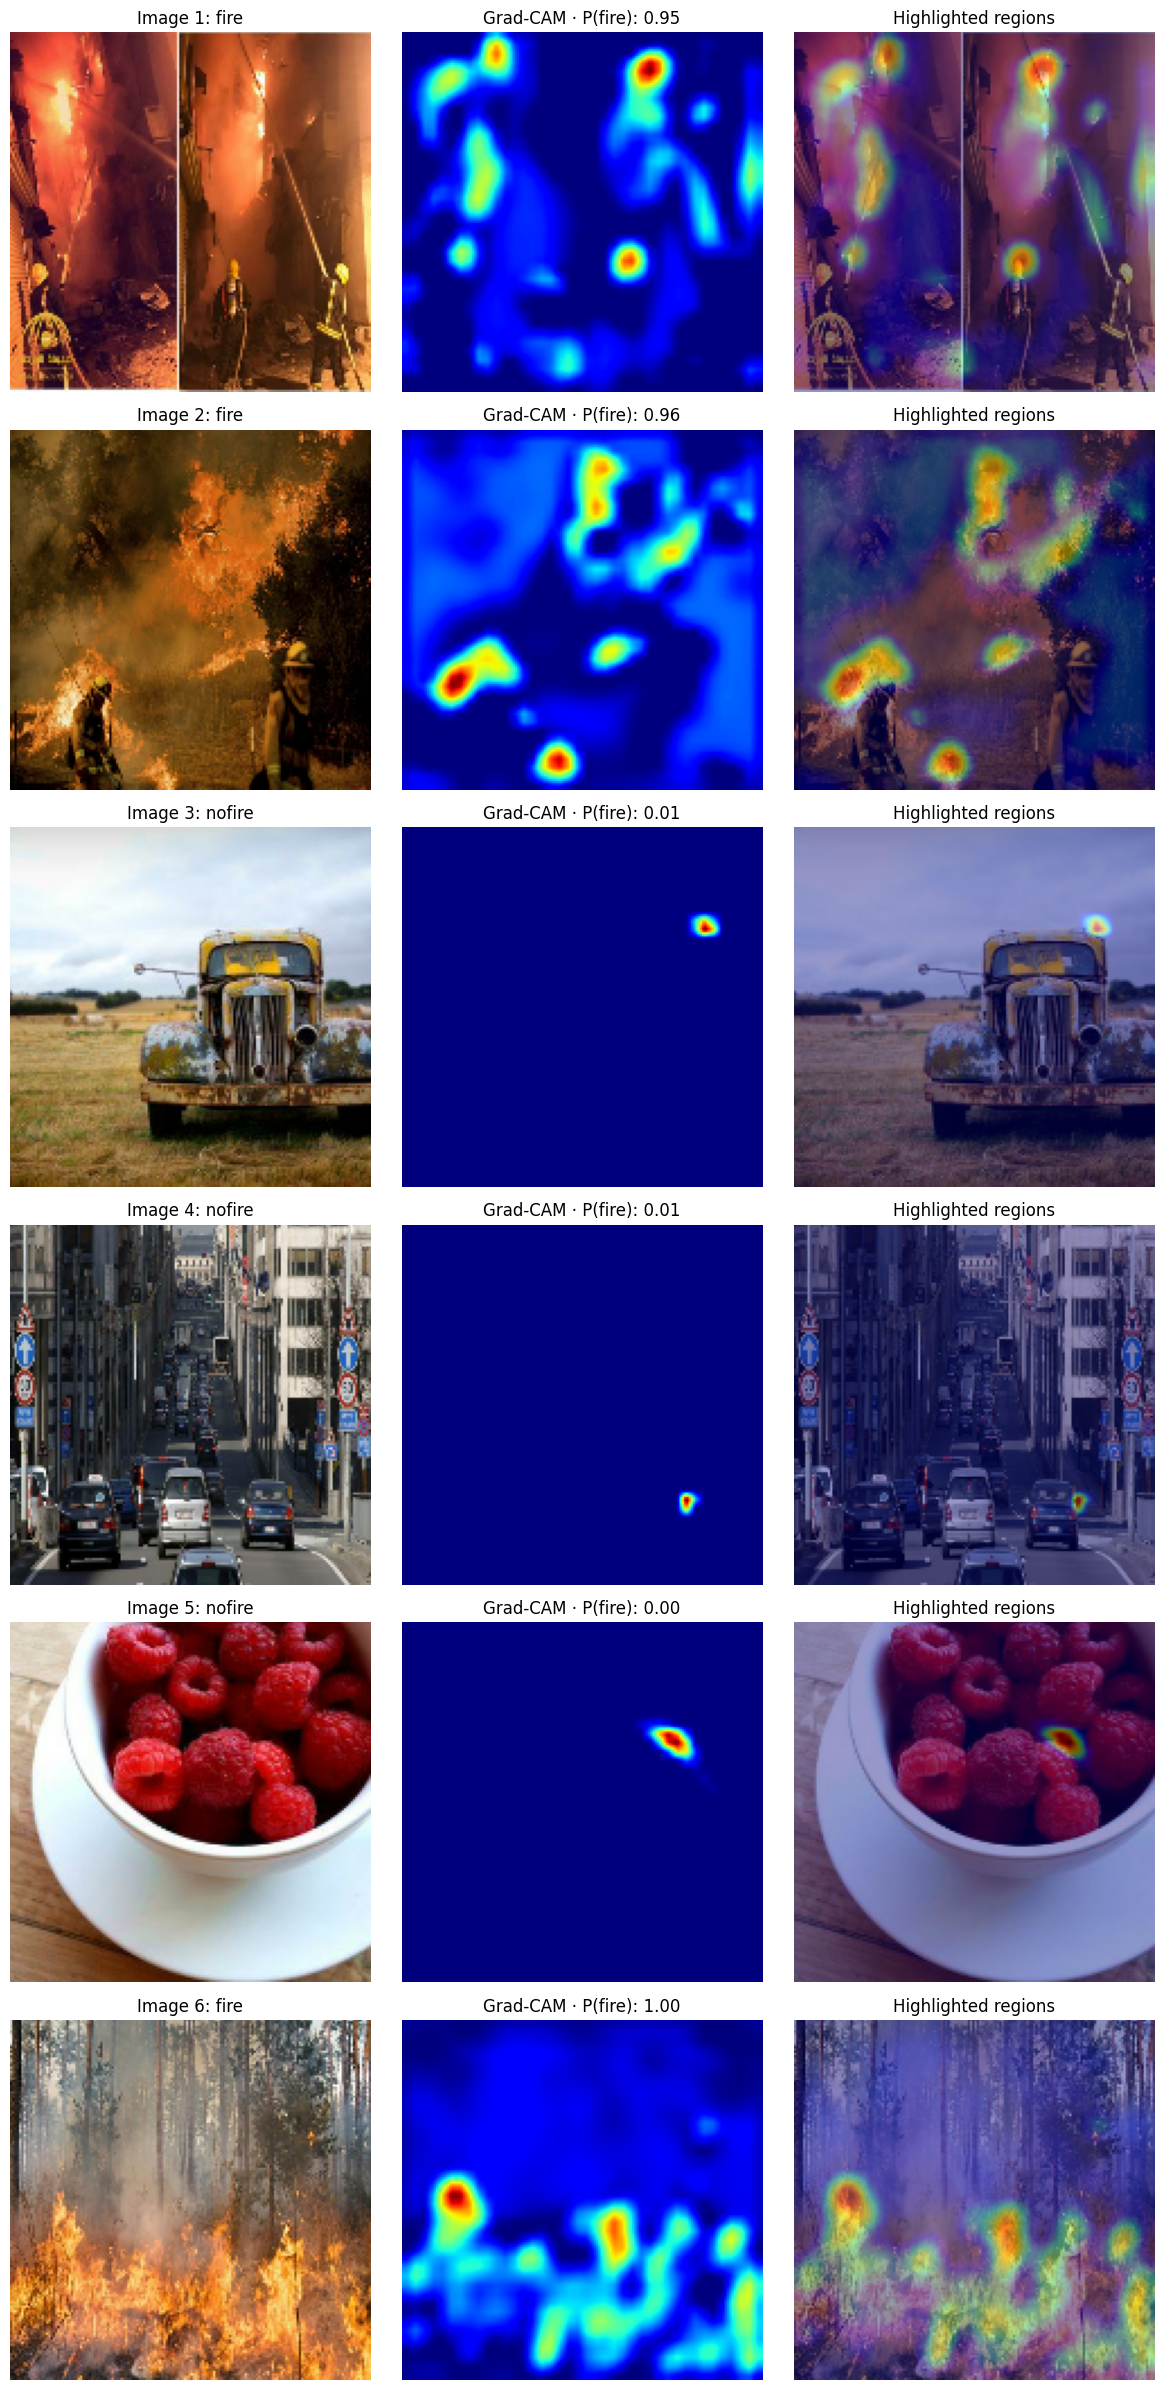

In [13]:
# Grad-CAM for multiple validation images
NUM_IMAGES = 6

image_batch, label_batch = next(iter(val_ds))
num_images = min(NUM_IMAGES, len(image_batch))

last_conv_layer = best_model.get_layer("relu_3_b")
grad_model = tf.keras.Model(
    inputs=best_model.inputs,
    outputs=[last_conv_layer.output, best_model.output]
)

plt.figure(figsize=(12, 4 * num_images))

for i in range(num_images):
    sample_image = image_batch[i:i + 1]
    true_class = int(label_batch[i].numpy()[0])

    with tf.GradientTape() as tape:
        conv_features, fire_score = grad_model(sample_image, training=False)
        target_score = fire_score[:, 0]

    gradients = tape.gradient(target_score, conv_features)
    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_features[0] * channel_weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], IMAGE_SIZE
    ).numpy().squeeze()

    original = sample_image[0].numpy().astype("uint8")
    probability = float(fire_score[0, 0])

    plt.subplot(num_images, 3, i * 3 + 1)
    plt.imshow(original)
    plt.title(f"Image {i + 1}: {CLASS_NAMES[true_class]}")
    plt.axis("off")

    plt.subplot(num_images, 3, i * 3 + 2)
    plt.imshow(heatmap, cmap="jet")
    plt.title(f"Grad-CAM · P(fire): {probability:.2f}")
    plt.axis("off")

    plt.subplot(num_images, 3, i * 3 + 3)
    plt.imshow(original)
    plt.imshow(heatmap, cmap="jet", alpha=0.40)
    plt.title("Highlighted regions")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Final test-set evaluation

Run this after training and validation-based analysis. The test set was held out from training and threshold selection. This cell evaluates it once at the stated 0.50 threshold for the final report.


Test accuracy: 94.41%
              precision    recall  f1-score   support

      nofire       0.91      0.98      0.95       185
        fire       0.98      0.91      0.94       191

    accuracy                           0.94       376
   macro avg       0.95      0.94      0.94       376
weighted avg       0.95      0.94      0.94       376



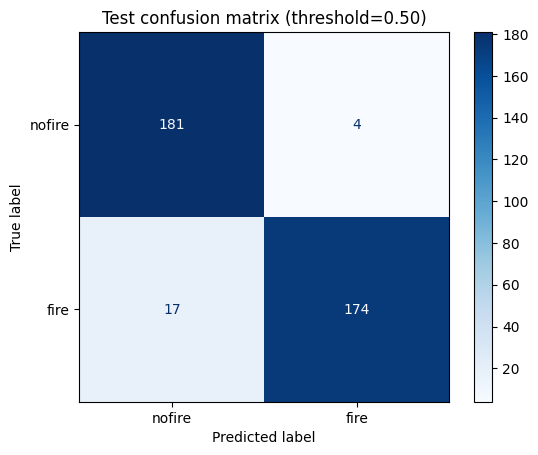

Test ROC AUC: 0.9875


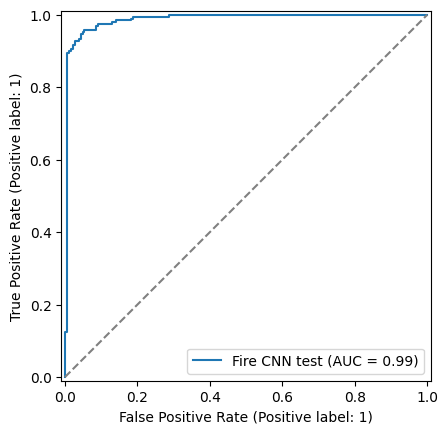

Saved final test metrics to: /content/drive/MyDrive/firewatch_artifacts/test_metrics.json


In [14]:
# Final, independent test evaluation at a prespecified 0.50 threshold.
TEST_THRESHOLD = 0.50
test_metrics = best_model.evaluate(test_ds, verbose=0, return_dict=True)
y_test = np.concatenate([labels.numpy().reshape(-1) for _, labels in test_ds]).astype(int)
y_test_score = best_model.predict(test_ds, verbose=0).reshape(-1)
y_test_pred = (y_test_score >= TEST_THRESHOLD).astype(int)

print(f"Test accuracy: {test_metrics['accuracy'] * 100:.2f}%")
print(classification_report(y_test, y_test_pred, target_names=CLASS_NAMES, zero_division=0))
test_cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
ConfusionMatrixDisplay(test_cm, display_labels=CLASS_NAMES).plot(cmap="Blues", values_format="d")
plt.title(f"Test confusion matrix (threshold={TEST_THRESHOLD:.2f})")
plt.show()
if len(np.unique(y_test)) == 2:
    test_auc = float(roc_auc_score(y_test, y_test_score))
    print("Test ROC AUC:", round(test_auc, 4))
    RocCurveDisplay.from_predictions(y_test, y_test_score, name="Fire CNN test")
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.show()
else:
    test_auc = None

test_summary = {
    "class_names": CLASS_NAMES,
    "threshold": TEST_THRESHOLD,
    "accuracy": float(test_metrics["accuracy"]),
    "loss": float(test_metrics["loss"]),
    "roc_auc": test_auc,
    "confusion_matrix_labels": CLASS_NAMES,
    "confusion_matrix": test_cm.tolist(),
}
(ARTIFACT_DIR / "test_metrics.json").write_text(json.dumps(test_summary, indent=2), encoding="utf-8")
print("Saved final test metrics to:", (ARTIFACT_DIR / "test_metrics.json").resolve())


## 8. Predict on a new image

Set `IMAGE_PATH` to a local JPG or PNG. The code displays the resized image and returns the predicted class and sigmoid score.


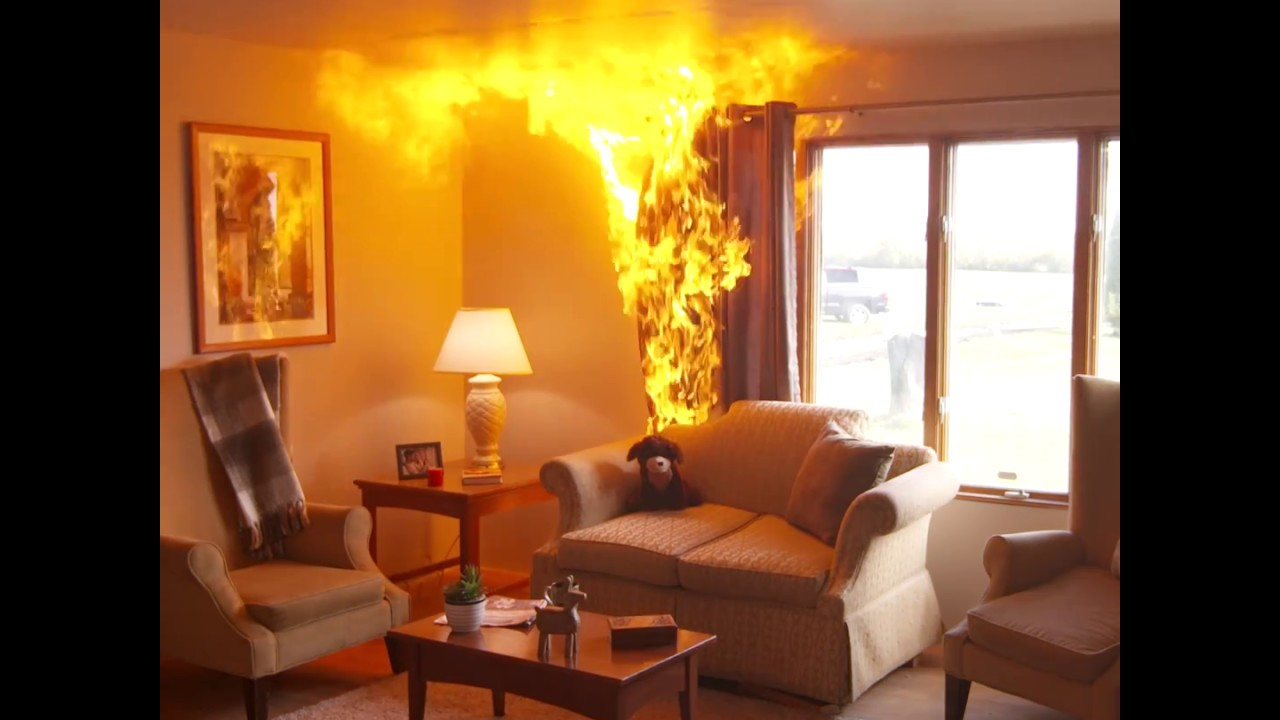

Prediction: fire
Estimated fire probability: 86.8%


In [16]:
from PIL import Image, UnidentifiedImageError

IMAGE_PATH = Path("/content/drive/MyDrive/fire in room.jpg")  # Change this to your test image.
if not IMAGE_PATH.is_file():
    print(f"Add a test image at {IMAGE_PATH.resolve()} or update IMAGE_PATH, then rerun this cell.")
else:
    image = Image.open(IMAGE_PATH).convert("RGB")
    resized = image.resize(IMAGE_SIZE)
    display(image)
    image_array = np.asarray(resized, dtype=np.float32)[None, ...]
    fire_probability = float(best_model.predict(image_array, verbose=0)[0][0])
    prediction_threshold = 0.50
    predicted_index = int(fire_probability >= prediction_threshold)
    print("Prediction:", CLASS_NAMES[predicted_index])
    print(f"Estimated fire probability: {fire_probability:.1%}")


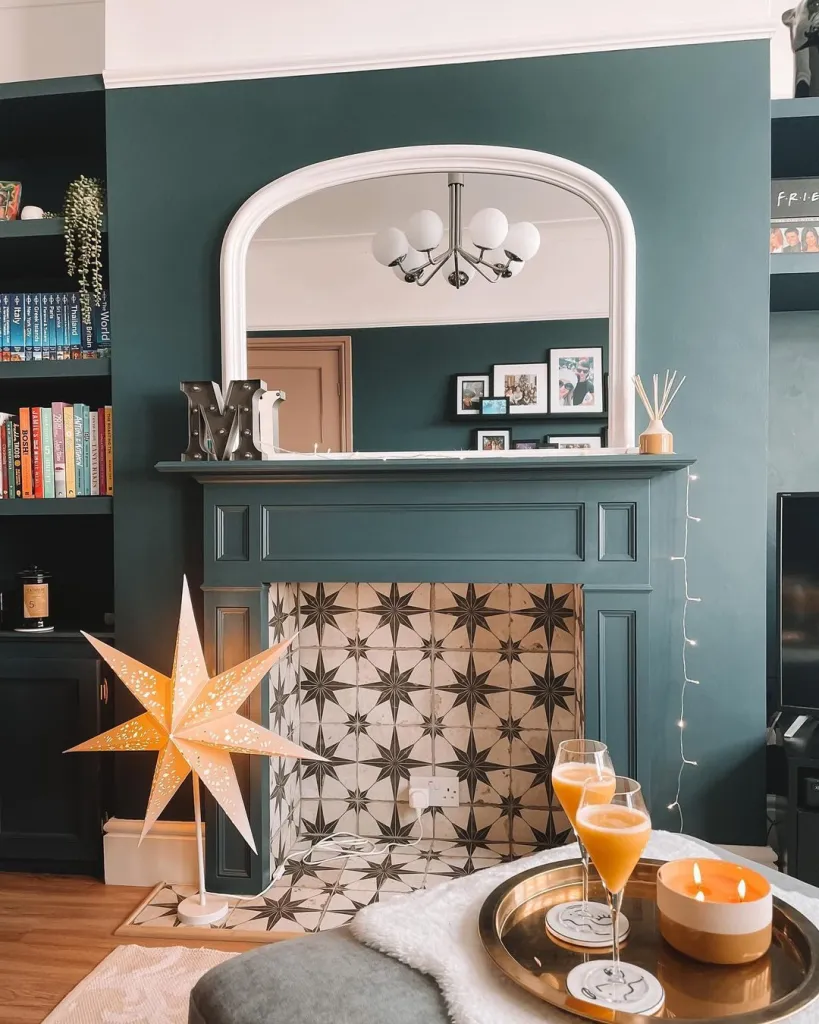

Prediction: nofire
Estimated fire probability: 0.2%


In [17]:
from PIL import Image, UnidentifiedImageError

IMAGE_PATH = Path("/content/drive/MyDrive/no fire image.webp")  # Change this to your test image.
if not IMAGE_PATH.is_file():
    print(f"Add a test image at {IMAGE_PATH.resolve()} or update IMAGE_PATH, then rerun this cell.")
else:
    image = Image.open(IMAGE_PATH).convert("RGB")
    resized = image.resize(IMAGE_SIZE)
    display(image)
    image_array = np.asarray(resized, dtype=np.float32)[None, ...]
    fire_probability = float(best_model.predict(image_array, verbose=0)[0][0])
    prediction_threshold = 0.50
    predicted_index = int(fire_probability >= prediction_threshold)
    print("Prediction:", CLASS_NAMES[predicted_index])
    print(f"Estimated fire probability: {fire_probability:.1%}")

## Discussion and next steps

- Document the dataset source, license, image counts, and any exclusions.
- Discuss likely error sources: smoke, fog, sunsets, orange lighting, reflections, distance, blur, and camera domain shift.
- Compare the class-wise metrics and describe the false-negative / false-positive trade-off.
- For a stronger evaluation, hold out complete videos, cameras, or locations rather than randomly splitting near-duplicate frames.
- Future work could use temporal CNN/RNN models over frame sequences, or object detection to localize flames.
